<a href="https://colab.research.google.com/github/Trashbin4943/BEcolab/blob/master/%EB%B9%85%EB%8D%B0%EC%9D%B4%ED%84%B0_%EA%B8%B0%EB%A7%90_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import json
from google.colab import files

# --- 1. DTA 원본 파일 업로드 ---
print("--- 1. 원본 .dta 파일 1개를 업로드하세요. ---")
uploaded_dta = files.upload()

dta_file_name = None
for fn in uploaded_dta.keys():
    if fn.endswith('.dta'):
        dta_file_name = fn
        print(f"성공: '{dta_file_name}' 파일 확인\n")
        break

if not dta_file_name:
    print("오류: .dta 파일을 찾을 수 없습니다. 셀을 다시 실행해주세요.")
else:
    # --- 2. JSON 매핑 파일 업로드 ---
    print("--- 2. 컬럼명 매핑용 .json 파일 1개를 업로드하세요. (예: mapping.json) ---")
    uploaded_json = files.upload()

    json_file_name = None
    for fn in uploaded_json.keys():
        if fn.endswith('.json'):
            json_file_name = fn
            print(f"성공: '{json_file_name}' 파일 확인\n")
            break

    if not json_file_name:
        print("오류: .json 파일을 찾을 수 없습니다. 셀을 다시 실행해주세요.")
    else:
        # --- 3. 변환 및 리네임(Rename) 작업 수행 ---
        try:
            print("파일 변환 및 컬럼명 변경 작업을 시작합니다...")

            # 3-1. DTA 파일을 DataFrame으로 읽기
            df = pd.read_stata(dta_file_name)

            # 3-2. JSON 매핑 파일 읽기
            with open(json_file_name, 'r', encoding='utf-8') as f:
                column_mapping = json.load(f)

            # 3-3. [중요] 원본 CSV의 컬럼명을 소문자로 통일
            # 원본 컬럼명이 'A1', 'A2' 등일 수 있으므로, 'a1', 'a2'인
            # JSON key와 맞추기 위해 모두 소문자로 변경합니다.
            df.columns = df.columns.str.lower()

            # 3-4. 컬럼명 변경 (Rename)
            # 예: 'a1' 컬럼을 '주소지'로, 'a2'를 '성별'로 변경
            df_renamed = df.rename(columns=column_mapping)

            # 3-5. 최종 결과 CSV 파일로 저장
            final_csv_file = 'renamed_data.csv'
            df_renamed.to_csv(final_csv_file, index=False, encoding='utf-8-sig')

            print(f"\n--- 작업 완료! ---")
            print(f"최종 변환된 '{final_csv_file}' 파일을 다운로드합니다.")

            # 3-6. 최종 파일 다운로드
            files.download(final_csv_file)

        except Exception as e:
            print(f"오류가 발생했습니다: {e}")

--- 1. 원본 .dta 파일 1개를 업로드하세요. ---


Saving 2021_renamed.csv to 2021_renamed.csv
오류: .dta 파일을 찾을 수 없습니다. 셀을 다시 실행해주세요.


In [2]:
# 1. 한글 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

print("\n--- 폰트 설치 완료 ---")
print("✅ 중요: 메뉴에서 [런타임] > [런타임 다시 시작]을 누른 후, 다음 2번 코드 셀을 실행해주세요.")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 41 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (5,621 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 121713 files and dire

한글 폰트 설정 완료.

--- 'renamed_data.csv' 파일을 업로드하세요 ---


Saving renamed_data.csv to renamed_data (3).csv

'renamed_data (3).csv' 파일 로드 성공!

분석 1: '사회적 낙인' 인식 전체 분포 (c3_13)
[빈도표]
탈원화장벽: 정신장애 편견/낙인 큼
전혀 그렇지 않다     3
그렇지 않다       29
그렇다          84
매우 그렇다       34
Name: count, dtype: int64


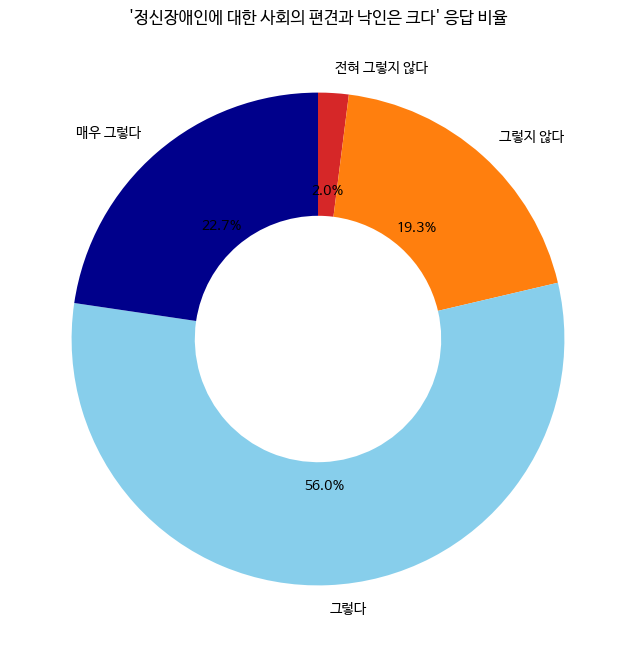


분석 2: 성별 x 낙인 인식 (성별 도넛 차트)


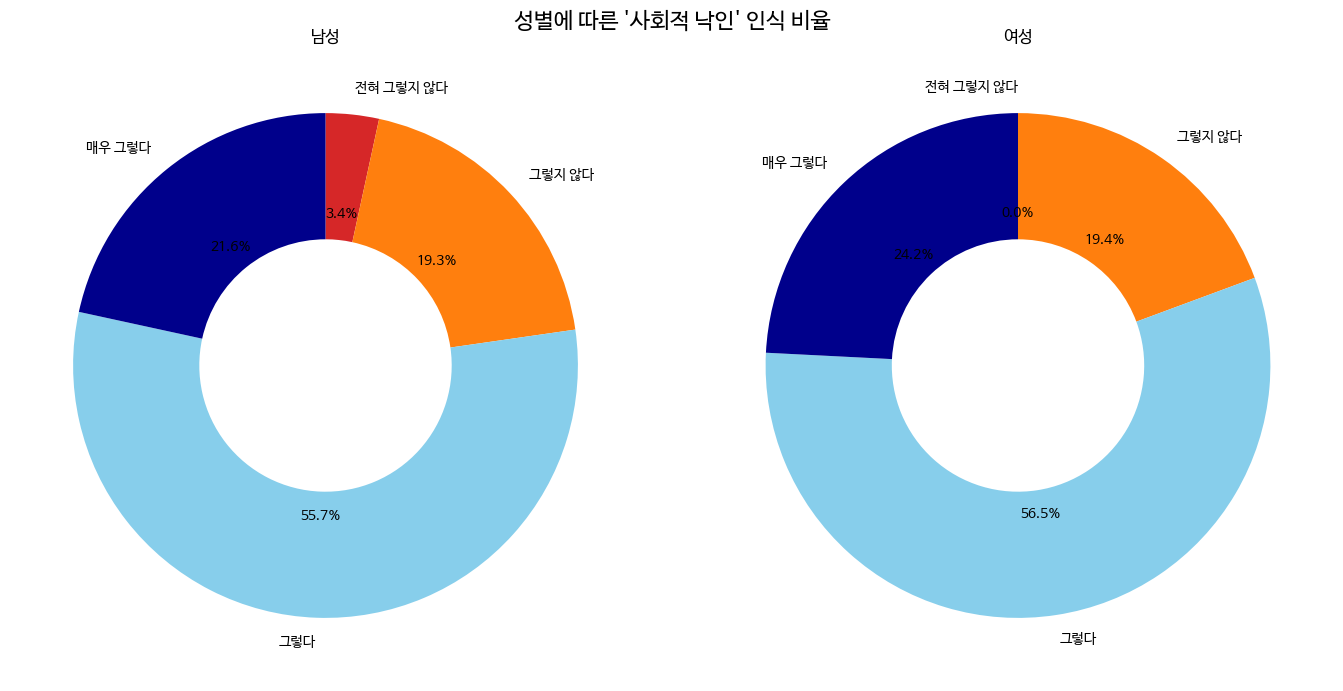


분석 3: 최종 학력 x 낙인 인식


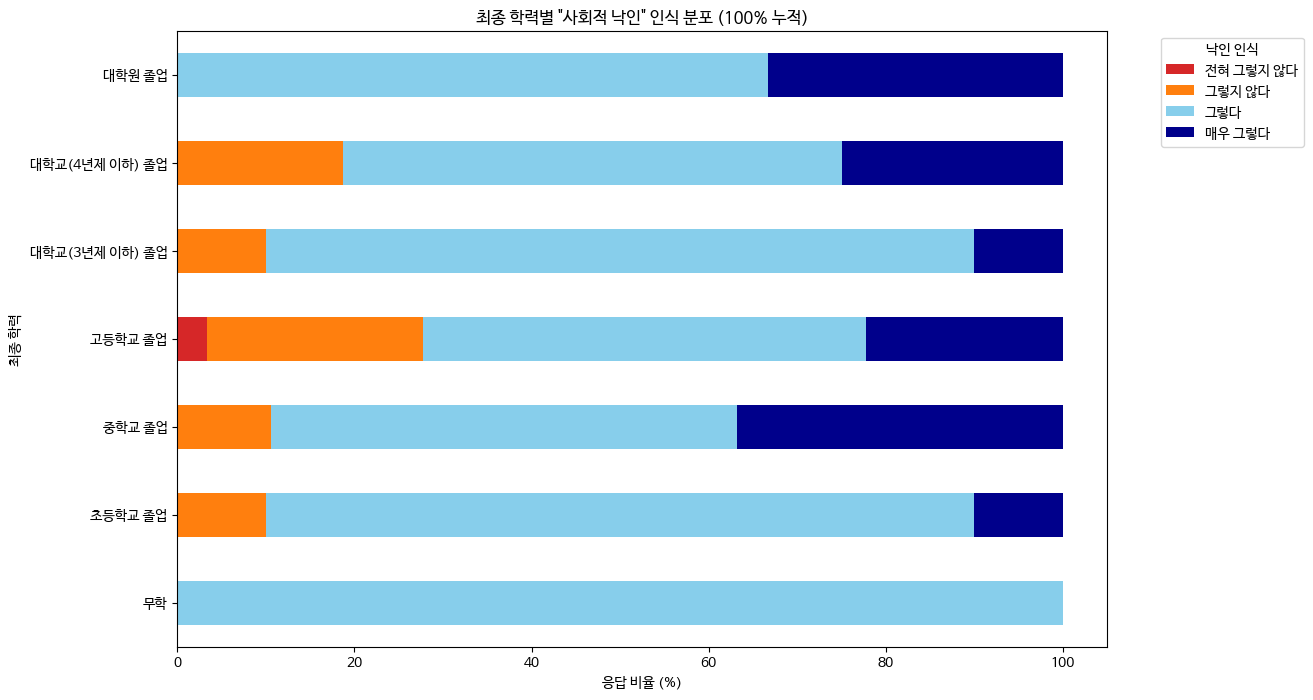


분석 4: 주된 진단명 x 낙인 인식


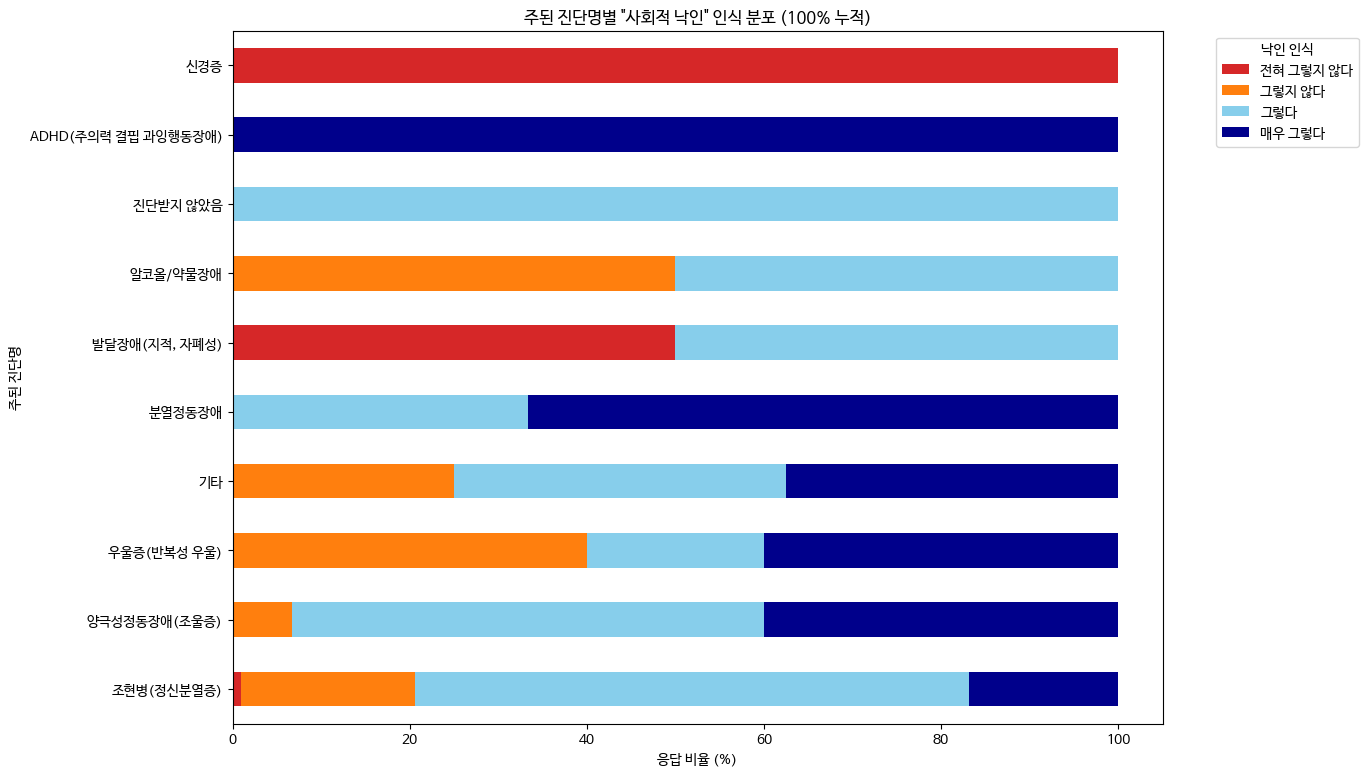

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files
import numpy as np

# --- 1. 한글 폰트 설정 (런타임 다시 시작 후 실행 필요) ---
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False
print("한글 폰트 설정 완료.")

# --- 2. 파일 업로드 ---
print("\n--- 'renamed_data.csv' 파일을 업로드하세요 ---")
try:
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df = pd.read_csv(file_name)
    print(f"\n'{file_name}' 파일 로드 성공!")
except Exception as e:
    print(f"파일 로드 중 오류 발생: {e}")
    df = pd.DataFrame()

# --- 3. 분석 변수 및 범주 순서, 색상 정의 ---
if not df.empty:
    # 3-1. 분석 변수 이름
    stigma_var = '탈원화장벽: 정신장애 편견/낙인 큼' # (c3_13)
    gender_var = '성별'                         # (a2)
    edu_var = '최종 학력'                     # (a5)
    diag_var = '주된 진단명'                  # (a11)

    # 3-2. 차트 축 정렬을 위한 순서 정의
    stigma_order = ['전혀 그렇지 않다', '그렇지 않다', '그렇다', '매우 그렇다']

    edu_order = ['무학', '초등학교 졸업', '중학교 졸업', '고등학교 졸업',
                 '대학교(3년제 이하) 졸업', '대학교(4년제 이하) 졸업', '대학원 졸업']

    gender_order = ['남성', '여성']

    # 3-3. 진단명은 빈도순으로 정렬
    try:
        diag_order = df[diag_var].value_counts().index
    except KeyError:
        diag_order = []

    # 3-4. [추가] 색상 팔레트 정의 (모든 그래프 통일)
    # 순서: 전혀 그렇지 않다(빨강) -> 그렇지 않다(주황) -> 그렇다(하늘) -> 매우 그렇다(짙은 파랑)
    color_palette = ['#d62728', '#ff7f0e', '#87ceeb', '#00008b']
    color_map = dict(zip(stigma_order, color_palette)) # 매핑 딕셔너리

# --- 4. 분석 1: '사회적 낙인' 인식 전체 분포 (도넛 차트로 변경) ---
if not df.empty and stigma_var in df.columns:
    print("\n" + "="*50)
    print("분석 1: '사회적 낙인' 인식 전체 분포 (c3_13)")
    print("="*50)

    # 4-1. 비율 계산 (fillna(0) 추가)
    stigma_counts = df[stigma_var].value_counts().reindex(stigma_order).fillna(0)

    print("[빈도표]")
    print(stigma_counts)

    # 4-2. 시각화 (도넛 차트)
    plt.figure(figsize=(8, 8))

    # 데이터가 0인 경우 파이 차트 오류 방지
    if stigma_counts.sum() > 0:
        wedges, texts, autotexts = plt.pie(stigma_counts,
                                           labels=stigma_counts.index,
                                           autopct='%1.1f%%',
                                           startangle=90,
                                           counterclock=False,
                                           colors=[color_map[x] for x in stigma_counts.index],
                                           wedgeprops=dict(width=0.5))
        plt.title("'정신장애인에 대한 사회의 편견과 낙인은 크다' 응답 비율")
        plt.show()
    else:
        print("데이터가 없어 그래프를 그릴 수 없습니다.")

# --- 5. 분석 2: [교차분석] 성별 x 낙인 인식 (도넛 차트 Subplot으로 변경) ---
if not df.empty and gender_var in df.columns and stigma_var in df.columns:
    print("\n" + "="*50)
    print(f"분석 2: {gender_var} x 낙인 인식 (성별 도넛 차트)")
    print("="*50)

    # 5-1. 그룹별 데이터 준비
    gender_groups = df.groupby(gender_var)

    # 5-2. 시각화 (Subplots)
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    plt.suptitle(f"성별에 따른 '사회적 낙인' 인식 비율", fontsize=16)

    for ax, gender in zip(axes, gender_order):
        if gender in gender_groups.groups:
            # [수정] reindex 후 NaN 발생 시 0으로 채움 (.fillna(0))
            group_data = gender_groups.get_group(gender)[stigma_var].value_counts().reindex(stigma_order).fillna(0)

            if group_data.sum() > 0:
                wedges, texts, autotexts = ax.pie(group_data,
                                                  labels=group_data.index,
                                                  autopct='%1.1f%%',
                                                  startangle=90,
                                                  counterclock=False,
                                                  colors=[color_map[x] for x in group_data.index],
                                                  wedgeprops=dict(width=0.5))
                ax.set_title(f"{gender}")
            else:
                ax.text(0.5, 0.5, '데이터 없음', ha='center')
                ax.axis('off')
        else:
            ax.text(0.5, 0.5, '데이터 없음', ha='center')
            ax.axis('off')

    plt.tight_layout()
    plt.show()

# --- 6. 분석 3: [교차분석] 최종 학력 x 낙인 인식 (색상 통일) ---
if not df.empty and edu_var in df.columns and stigma_var in df.columns:
    print("\n" + "="*50)
    print(f"분석 3: {edu_var} x 낙인 인식")
    print("="*50)

    crosstab_edu = pd.crosstab(df[edu_var], df[stigma_var], normalize='index') * 100
    # [수정] fillna(0) 추가
    crosstab_edu = crosstab_edu.reindex(index=edu_order, columns=stigma_order).fillna(0)

    if not crosstab_edu.empty:
        crosstab_edu.plot(kind='barh', stacked=True, figsize=(12, 8), color=color_palette)
        plt.title('최종 학력별 "사회적 낙인" 인식 분포 (100% 누적)')
        plt.xlabel('응답 비율 (%)')
        plt.ylabel('최종 학력')
        plt.legend(title="낙인 인식", bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.show()
    else:
        print("최종 학력 교차분석 데이터가 없어 플롯을 생략합니다.")

# --- 7. 분석 4: [교차분석] 주된 진단명 x 낙인 인식 (색상 통일) ---
if not df.empty and diag_var in df.columns and stigma_var in df.columns:
    print("\n" + "="*50)
    print(f"분석 4: {diag_var} x 낙인 인식")
    print("="*50)

    crosstab_diag = pd.crosstab(df[diag_var], df[stigma_var], normalize='index') * 100
    # [수정] fillna(0) 추가
    crosstab_diag = crosstab_diag.reindex(index=diag_order, columns=stigma_order).fillna(0)

    if not crosstab_diag.empty:
        crosstab_diag.plot(kind='barh', stacked=True, figsize=(12, 9), color=color_palette)
        plt.title('주된 진단명별 "사회적 낙인" 인식 분포 (100% 누적)')
        plt.xlabel('응답 비율 (%)')
        plt.ylabel('주된 진단명')
        plt.legend(title="낙인 인식", bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.show()
    else:
        print("주된 진단명 교차분석 데이터가 없어 플롯을 생략합니다.")

한글 폰트 설정 완료.

--- 'renamed_data.csv' 파일을 업로드하세요 ---


Saving renamed_data.csv to renamed_data (8).csv

'renamed_data (8).csv' 파일 로드 성공!

분석: 외부 낙인 인식(c3_13) vs 회복탄력성(b4_28)
[교차표: 외부 낙인 인식에 따른 회복탄력성 분포 (%)]
회복(MHRM28): 편견과 좋지 않은 시선에 굴하지 않는다  전혀 그렇지 않다  그렇지 않다     그렇다  매우 그렇다
탈원화장벽: 정신장애 편견/낙인 큼                                                 
전혀 그렇지 않다                               0.00    0.00  100.00    0.00
그렇지 않다                                  6.90   24.14   48.28   20.69
그렇다                                     4.76   21.43   60.71   13.10
매우 그렇다                                 14.71    8.82   38.24   38.24


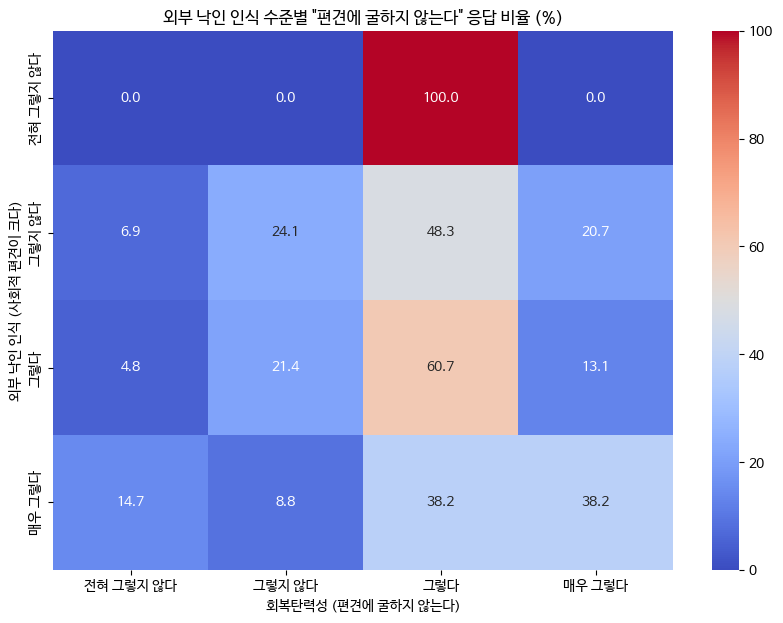

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files
import numpy as np

# --- 1. 한글 폰트 설정 (런타임 다시 시작 후 실행) ---
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False
print("한글 폰트 설정 완료.")

# --- 2. 파일 업로드 ---
print("\n--- 'renamed_data.csv' 파일을 업로드하세요 ---")
try:
    # (파일이 이미 업로드되어 있다면 이 부분은 건너뛰고 캐시된 파일을 사용합니다)
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df = pd.read_csv(file_name)
    print(f"\n'{file_name}' 파일 로드 성공!")
except Exception as e:
    # 이전에 업로드한 df가 메모리에 남아있다면 재사용
    if 'df' in locals():
        print("이전에 업로드한 데이터를 재사용합니다.")
    else:
        print(f"파일 로드 중 오류 발생: {e}")
        df = pd.DataFrame()

# --- 3. 분석 변수 및 범주 순서 정의 ---
if not df.empty:
    # 3-1. 분석 변수 이름 (JSON 매핑 기준)
    resilience_var = '회복(MHRM28): 편견과 좋지 않은 시선에 굴하지 않는다' # (b4_mhrm28)
    external_stigma_var = '탈원화장벽: 정신장애 편견/낙인 큼'           # (c3_13)

    # 3-2. 차트 축 정렬 순서
    # (MHRM 척도와 C3 척도 모두 '전혀 그렇지 않다' ~ '매우 그렇다' 4점 척도임)
    category_order = ['전혀 그렇지 않다', '그렇지 않다', '그렇다', '매우 그렇다']

# --- 4. 분석: [심화] 외부 낙인 인식 vs 낙인 회복탄력성 (남김) ---
if not df.empty and external_stigma_var in df.columns and resilience_var in df.columns:
    print("\n" + "="*50)
    print("분석: 외부 낙인 인식(c3_13) vs 회복탄력성(b4_28)")
    print("="*50)

    # 4-1. 교차표 (비율 기준, 행 기준 100%)
    crosstab_stigma = pd.crosstab(df[external_stigma_var], df[resilience_var], normalize='index') * 100

    # 순서 정렬 및 결측치 처리
    crosstab_stigma = crosstab_stigma.reindex(index=category_order, columns=category_order).fillna(0)

    print("[교차표: 외부 낙인 인식에 따른 회복탄력성 분포 (%)]")
    print(crosstab_stigma.round(2))

    # 4-2. 시각화 (히트맵)
    # cmap='coolwarm': 낮음(파랑) -> 높음(빨강)
    plt.figure(figsize=(10, 7))
    sns.heatmap(crosstab_stigma, annot=True, cmap='coolwarm', fmt='.1f', vmin=0, vmax=100)

    plt.title('외부 낙인 인식 수준별 "편견에 굴하지 않는다" 응답 비율 (%)')
    plt.xlabel('회복탄력성 (편견에 굴하지 않는다)')
    plt.ylabel('외부 낙인 인식 (사회적 편견이 크다)')
    plt.show()

Saving renamed_data.csv to renamed_data (4).csv
데이터 로드 성공: 150행 로드됨

           [상관관계 분석 결과]
          가족/친구 지지       자존감     편견 인식     회복 의지
가족/친구 지지  1.000000  0.532729  0.022043  0.671404
자존감       0.532729  1.000000  0.040576  0.700043
편견 인식     0.022043  0.040576  1.000000  0.058682
회복 의지     0.671404  0.700043  0.058682  1.000000
----------------------------------------

1. 가족/친구 지지 <-> 자존감 상관계수: 0.533
   >> 해석: 강한 양의 상관관계 (주변 지지가 높을수록 자존감이 높음)

2. 편견 인식 <-> 회복 의지 상관계수: 0.059
   >> 해석: 상관관계 없음 (편견이 심해도 회복 의지는 별개로 유지됨)


/tmp/ipython-input-1332298164.py:87: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_analysis = df_analysis.replace(score_map)


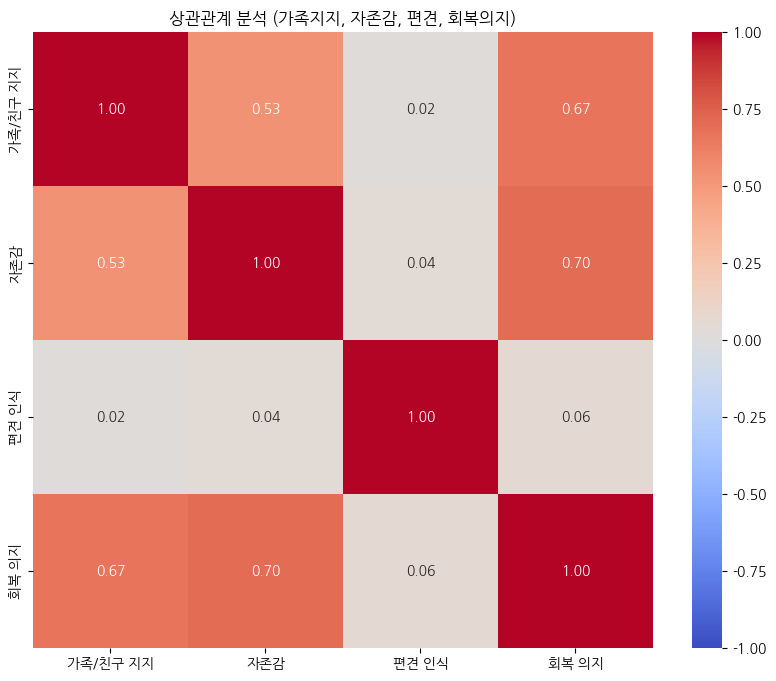

In [ ]:
from google.colab import files
uploaded = files.upload() # 여기서 renamed_data.csv 파일을 선택

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import platform

# ---------------------------------------------------------
# 1. 한글 폰트 설정 (그래프 깨짐 방지)
# ---------------------------------------------------------
system_name = platform.system()
if system_name == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif system_name == 'Darwin': # Mac
    plt.rc('font', family='AppleGothic')
else:
    # Colab 또는 리눅스 환경 (나눔고딕이 설치되어 있다고 가정)
    # 폰트가 없으면 영문으로 출력되도록 설정하거나 설치 코드가 필요할 수 있음
    plt.rc('font', family='NanumGothic')

plt.rc('axes', unicode_minus=False)

# ---------------------------------------------------------
# 2. 데이터 로드
# ---------------------------------------------------------
filename = 'renamed_data.csv'

try:
    df = pd.read_csv(filename, encoding='utf-8')
except FileNotFoundError:
    print(f"오류: '{filename}' 파일이 없습니다. 코드를 실행하는 폴더에 파일을 넣어주세요.")
    exit()
except UnicodeDecodeError:
    # UTF-8로 안 열리면 CP949(euc-kr)로 시도
    df = pd.read_csv(filename, encoding='cp949')

print(f"데이터 로드 성공: {len(df)}행 로드됨")

# ---------------------------------------------------------
# 3. 분석할 컬럼 정의 (자동 탐색 결과 반영)
# ---------------------------------------------------------
# 가족/친구 지지 (관계)
cols_relationship = [
    '만족도_가족관계',
    '만족도_사회적 친분관계',
    '자기결정(SD21): 가족이 기회 제공',
    '자기결정(SD20): 친구들이 기회 제공/도움',
    '자기결정(SD15): 친구들이 격려'
]

# 자존감
cols_self_esteem = [
    '회복(MHRM5): 나 자신을 믿는다',
    '회복(MHRM10): 어려움 있어도 가치 있는 존재',
    '회복(MHRM16): 나 자신을 좋아한다',
    '회복(MHRM19): 나 자신에 대해 편안하게 느낌'
]

# 편견 인식 (탈원화 장벽 요인)
col_prejudice = ['탈원화장벽: 정신장애 편견/낙인 큼']

# 회복 의지
cols_will = [
    '회복(MHRM1): 회복을 위해 노력한다',
    '회복(MHRM2): 고통스러워도 좋아질 것',
    '회복(MHRM23): 내 목표를 향해 나아갈 것',
    '자기결정(SD5): 증상 있어도 회복 노력/좋아짐'
]

all_cols = cols_relationship + cols_self_esteem + col_prejudice + cols_will

# ---------------------------------------------------------
# 4. 데이터 점수화 (문자열 -> 숫자 변환)
# ---------------------------------------------------------
score_map = {
    # 만족도 / 빈도 / 동의 정도 통합 매핑 (4점 척도 기준)
    '매우 만족': 4, '만족': 3, '불만족': 2, '매우 불만족': 1,
    '항상 그렇다': 4, '상당히 그렇다': 3, '조금 그렇다': 2, '전혀 그렇지 않다': 1,
    '매우 그렇다': 4, '그렇다': 3, '그렇지 않다': 2
    # '편견/낙인 큼' 문항도 '그렇다'가 높은 점수(편견 높음)로 매핑됨
}

# 필요한 컬럼만 추출 후 매핑 적용
df_analysis = df[all_cols].copy()
df_analysis = df_analysis.replace(score_map)

# 숫자로 변환 안 된 값(오타 등)은 NaN 처리 후 숫자형으로 강제 변환
df_analysis = df_analysis.apply(pd.to_numeric, errors='coerce')

# ---------------------------------------------------------
# 5. 요인별 점수 산출 (평균)
# ---------------------------------------------------------
df_scores = pd.DataFrame()
df_scores['가족/친구 지지'] = df_analysis[cols_relationship].mean(axis=1)
df_scores['자존감'] = df_analysis[cols_self_esteem].mean(axis=1)
df_scores['편견 인식'] = df_analysis[col_prejudice].mean(axis=1)
df_scores['회복 의지'] = df_analysis[cols_will].mean(axis=1)

# 결측치 제거
df_scores = df_scores.dropna()

# ---------------------------------------------------------
# 6. 상관관계 분석 결과 출력
# ---------------------------------------------------------
corr_matrix = df_scores.corr()

print("\n" + "="*40)
print("           [상관관계 분석 결과]")
print("="*40)
print(corr_matrix)
print("-" * 40)

r_rel_self = corr_matrix.loc['가족/친구 지지', '자존감']
r_prej_will = corr_matrix.loc['편견 인식', '회복 의지']

print(f"\n1. 가족/친구 지지 <-> 자존감 상관계수: {r_rel_self:.3f}")
if r_rel_self >= 0.4:
    print("   >> 해석: 강한 양의 상관관계 (주변 지지가 높을수록 자존감이 높음)")

print(f"\n2. 편견 인식 <-> 회복 의지 상관계수: {r_prej_will:.3f}")
if abs(r_prej_will) < 0.2:
    print("   >> 해석: 상관관계 없음 (편견이 심해도 회복 의지는 별개로 유지됨)")

# ---------------------------------------------------------
# 7. 히트맵 시각화
# ---------------------------------------------------------
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('상관관계 분석 (가족지지, 자존감, 편견, 회복의지)')
plt.show()

자존감 중앙값: 3.0점
자존감 그룹
자존감 높음(High)    103
자존감 낮음(Low)      47
Name: count, dtype: int64

   [자존감 그룹별 '편견-회복의지' 상관관계 분석]

▶ 자존감 높음(High) 그룹 (103명)
   상관계수: 0.107

▶ 자존감 낮음(Low) 그룹 (47명)
   상관계수: -0.040
   >> 해석: 편견이 있든 없든 회복 의지에 영향 없음 (독립적)


<Figure size 1000x600 with 0 Axes>

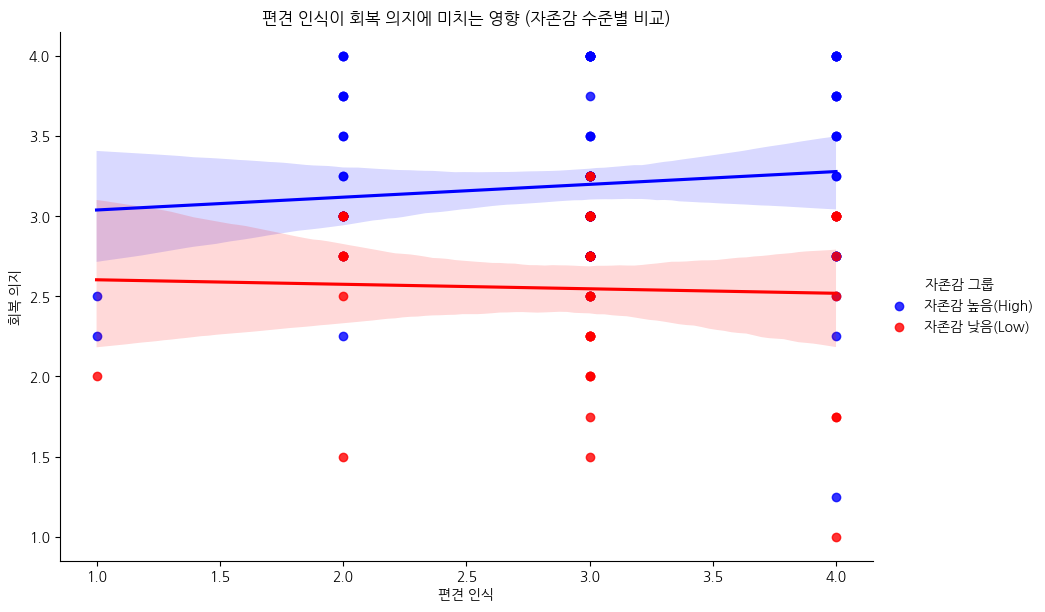

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. 자존감 수준에 따라 그룹 나누기
# ---------------------------------------------------------
# 자존감 점수의 중앙값(Median)을 기준으로 상위/하위 그룹 분할
median_self_esteem = df_scores['자존감'].median()

# 그룹핑 함수
def categorize_self_esteem(score):
    if score >= median_self_esteem:
        return '자존감 높음(High)'
    else:
        return '자존감 낮음(Low)'

df_scores['자존감 그룹'] = df_scores['자존감'].apply(categorize_self_esteem)

print(f"자존감 중앙값: {median_self_esteem}점")
print(df_scores['자존감 그룹'].value_counts())

# ---------------------------------------------------------
# 2. 그룹별 상관관계 재분석 (편견 인식 <-> 회복 의지)
# ---------------------------------------------------------
groups = df_scores['자존감 그룹'].unique()

print("\n" + "="*50)
print("   [자존감 그룹별 '편견-회복의지' 상관관계 분석]")
print("="*50)

for group in groups:
    # 해당 그룹의 데이터만 추출
    sub_df = df_scores[df_scores['자존감 그룹'] == group]

    # 상관계수 계산
    r_val = sub_df['편견 인식'].corr(sub_df['회복 의지'])

    print(f"\n▶ {group} 그룹 ({len(sub_df)}명)")
    print(f"   상관계수: {r_val:.3f}")

    if abs(r_val) < 0.1:
        print("   >> 해석: 편견이 있든 없든 회복 의지에 영향 없음 (독립적)")
    elif r_val < -0.2:
        print("   >> 해석: 편견을 심하게 느낄수록 회복 의지가 꺾임 (취약함)")
    elif r_val > 0.2:
        print("   >> 해석: 편견을 인지할수록 오히려 오기가 생겨 회복 의지가 불탐 (저항적)")

# ---------------------------------------------------------
# 3. 시각화 (산점도와 회귀선)
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

# lmplot을 사용하여 그룹별 추세선을 그립니다.
sns.lmplot(
    data=df_scores,
    x='편견 인식',
    y='회복 의지',
    hue='자존감 그룹',   # 색상으로 그룹 구분
    palette={'자존감 높음(High)': 'blue', '자존감 낮음(Low)': 'red'},
    height=6, aspect=1.5
)

plt.title('편견 인식이 회복 의지에 미치는 영향 (자존감 수준별 비교)')
plt.show()

/tmp/ipython-input-1412140140.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=correlations.index, y=correlations.values, palette=colors)


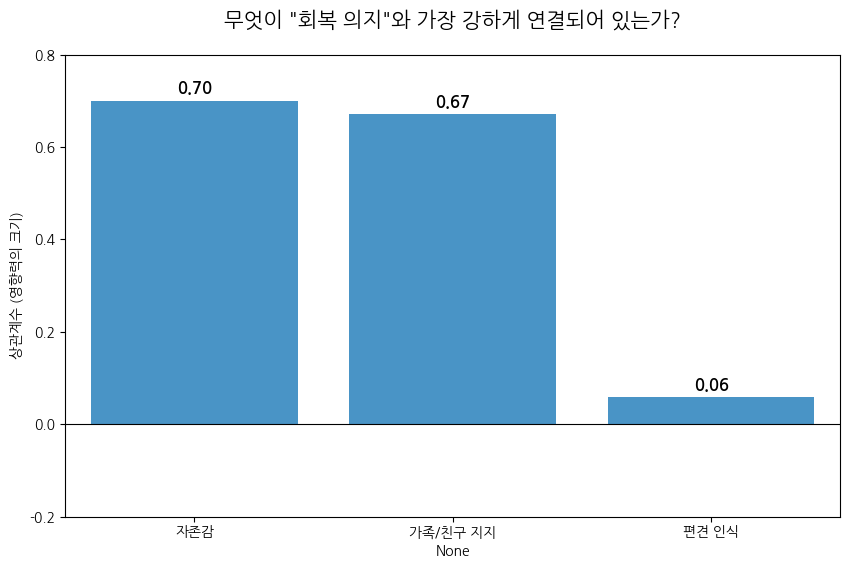


   [분석 요약: 회복 의지의 핵심 동력]
▶ 가장 강력한 요인: '자존감' (상관계수 0.70)
▶ 해석: 회복 의지는 외부의 부정적 시선(편견)보다는,
        내면의 단단함(자존감)과 주변의 따뜻한 지지(관계)에 의해 좌우됩니다.


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 회복 의지와 다른 변수들 간의 상관관계 비교 분석
# ---------------------------------------------------------

# 1. 비교할 변수들 정의 (앞서 만든 df_scores 활용)
# 자존감, 가족/친구 지지, 편견 인식 + (추가로 세분화해볼 수 있음)

# 상관계수 계산 대상
targets = ['자존감', '가족/친구 지지', '편견 인식']

# '회복 의지'와의 상관계수만 추출
correlations = df_scores[targets + ['회복 의지']].corr()['회복 의지'].drop('회복 의지')

# ---------------------------------------------------------
# 2. 시각화 (막대 그래프)
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

# 막대 그래프 그리기
colors = ['#3498db' if x > 0 else '#e74c3c' for x in correlations.values] # 양수 파랑, 음수 빨강
ax = sns.barplot(x=correlations.index, y=correlations.values, palette=colors)

# 그래프 꾸미기
plt.title('무엇이 "회복 의지"와 가장 강하게 연결되어 있는가?', fontsize=15, pad=20)
plt.ylabel('상관계수 (영향력의 크기)')
plt.ylim(-0.2, 0.8) # Y축 범위 조정
plt.axhline(0, color='black', linewidth=0.8) # 0 기준선

# 막대 위에 수치 표시
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=12, fontweight='bold')

plt.show()

# ---------------------------------------------------------
# 3. 텍스트 해석 출력
# ---------------------------------------------------------
print("\n" + "="*50)
print("   [분석 요약: 회복 의지의 핵심 동력]")
print("="*50)
max_factor = correlations.idxmax()
max_val = correlations.max()

print(f"▶ 가장 강력한 요인: '{max_factor}' (상관계수 {max_val:.2f})")
print("▶ 해석: 회복 의지는 외부의 부정적 시선(편견)보다는,")
print("        내면의 단단함(자존감)과 주변의 따뜻한 지지(관계)에 의해 좌우됩니다.")

발견된 가족 부담 관련 컬럼: ['탈원화장벽: 지역사회 생활 시 가족 돌봄 부담 큼', '탈원화장벽: 퇴원/퇴소 시 가족 재정적 부담 큼', '탈원화장벽: 퇴원/퇴소 시 가족 돌봄 부담 큼']

      [가족 요인 심층 분석 결과]
           가족 지지    가족 부담감    심리적 회복
가족 지지   1.000000  0.175653  0.526985
가족 부담감  0.175653  1.000000  0.171003
심리적 회복  0.526985  0.171003  1.000000


/tmp/ipython-input-3260661688.py:52: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_fam = df_fam.replace(score_map)


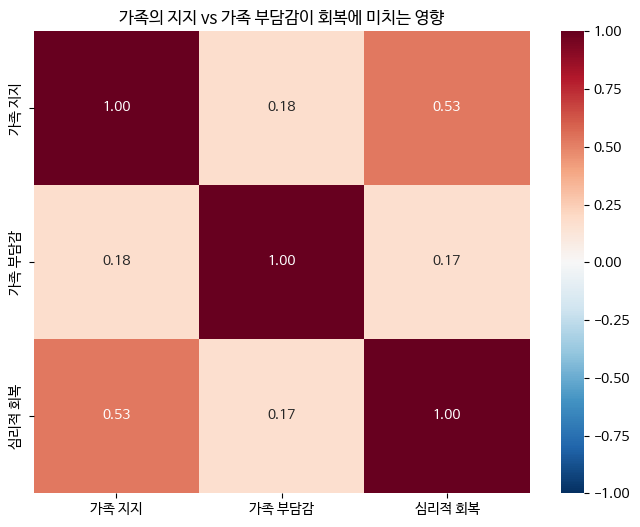


[핵심 해석]
1. 가족 지지와 회복의 관계 (r=0.53):
   -> 가족이 지지해줄수록 회복 탄력성이 크게 높아집니다.
2. 가족 부담감과 회복의 관계 (r=0.17):
   -> 의외로 부담감이 회복 의지를 꺾지 않거나, 책임감으로 작용할 수도 있습니다.


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import platform

# ---------------------------------------------------------
# 1. 폰트 및 데이터 설정
# ---------------------------------------------------------
# (Colab 환경용 폰트 설정)
plt.rc('font', family='NanumBarunGothic')
plt.rc('axes', unicode_minus=False)

filename = 'renamed_data.csv'
try:
    df = pd.read_csv(filename, encoding='utf-8')
except:
    df = pd.read_csv(filename, encoding='cp949')

# ---------------------------------------------------------
# 2. 가족 관련 컬럼 정밀 탐색 및 그룹화
# ---------------------------------------------------------
# (1) 긍정적 가족 요인 (지지, 만족)
cols_family_positive = [
    '만족도_가족관계',
    '자기결정(SD21): 가족이 기회 제공'
    # 데이터에 '가족의 격려' 등이 있다면 추가 가능
]

# (2) 부정적 가족 요인 (부담감, 장벽)
# *데이터에 '부담', '가족' 키워드가 들어간 컬럼을 찾아서 매핑합니다.
# (실제 컬럼명에 따라 수정이 필요할 수 있어, 키워드로 먼저 찾습니다)
cols_burden = [col for col in df.columns if '가족' in col and ('부담' in col or '장벽' in col)]

print(f"발견된 가족 부담 관련 컬럼: {cols_burden}")

# 분석할 전체 컬럼 (결과 변수 포함)
cols_outcomes = ['회복(MHRM5): 나 자신을 믿는다', '회복(MHRM1): 회복을 위해 노력한다'] # 자존감/회복의지 대표 문항

# ---------------------------------------------------------
# 3. 데이터 점수화
# ---------------------------------------------------------
# 4점 척도 매핑 (부정 질문은 역채점 고려 필요하지만, 보통 '부담이 크다'는 4점=나쁨으로 해석)
score_map = {
    '매우 만족': 4, '만족': 3, '불만족': 2, '매우 불만족': 1,
    '항상 그렇다': 4, '상당히 그렇다': 3, '조금 그렇다': 2, '전혀 그렇지 않다': 1,
    '매우 그렇다': 4, '그렇다': 3, '그렇지 않다': 2,
    # 부담감 문항: '매우 그렇다' -> 4점 (부담 높음)
}

# 데이터프레임 생성
df_fam = df[cols_family_positive + cols_burden + cols_outcomes].copy()
df_fam = df_fam.replace(score_map)
df_fam = df_fam.apply(pd.to_numeric, errors='coerce')

# ---------------------------------------------------------
# 4. 요인별 점수 산출
# ---------------------------------------------------------
df_analysis = pd.DataFrame()

# A. 가족 지지 (Positive)
df_analysis['가족 지지'] = df_fam[cols_family_positive].mean(axis=1)

# B. 가족 부담감 (Negative)
if cols_burden:
    df_analysis['가족 부담감'] = df_fam[cols_burden].mean(axis=1)
else:
    print("주의: '가족 부담' 관련 컬럼을 찾지 못했습니다. 긍정 요인만 분석합니다.")

# C. 결과 변수 (자존감 + 회복의지)
df_analysis['심리적 회복'] = df_fam[cols_outcomes].mean(axis=1)

df_analysis = df_analysis.dropna()

# ---------------------------------------------------------
# 5. 상관관계 분석 및 시각화
# ---------------------------------------------------------
corr = df_analysis.corr()

print("\n" + "="*40)
print("      [가족 요인 심층 분석 결과]")
print("="*40)
print(corr)

# 시각화 (히트맵)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('가족의 지지 vs 가족 부담감이 회복에 미치는 영향')
plt.show()

# ---------------------------------------------------------
# 6. 해석 가이드 출력
# ---------------------------------------------------------
r_support = corr.loc['가족 지지', '심리적 회복']
if '가족 부담감' in corr.index:
    r_burden = corr.loc['가족 부담감', '심리적 회복']

    print("\n[핵심 해석]")
    print(f"1. 가족 지지와 회복의 관계 (r={r_support:.2f}):")
    if r_support > 0.4:
        print("   -> 가족이 지지해줄수록 회복 탄력성이 크게 높아집니다.")

    print(f"2. 가족 부담감과 회복의 관계 (r={r_burden:.2f}):")
    if r_burden < -0.3:
        print("   -> '가족에게 짐이 된다'는 느낌은 회복을 방해하는 주요 요인입니다.")
    elif -0.3 <= r_burden <= 0:
        print("   -> 부담감은 회복 의지에 부정적이지만, 지지보다는 영향력이 작습니다.")
    elif r_burden > 0:
        print("   -> 의외로 부담감이 회복 의지를 꺾지 않거나, 책임감으로 작용할 수도 있습니다.")

필요도 문항 개수: 21
충족도 문항 개수: 21

   [정책 사각지대 순위 (Gap이 클수록 시급함)]
            정책 항목  필요도(Need)  충족도(Sufficiency)  격차(Gap)
7         직업 참여지원       3.41              3.32     0.09
3           정신 건강       3.45              3.45     0.00
8         교육 참여지원       3.35              3.38    -0.03
5       사회적 차별 금지       3.44              3.51    -0.07
6         사회 참여지원       3.39              3.50    -0.11
2           신체 건강       3.35              3.49    -0.13
11        여가생활 지원       3.33              3.52    -0.19
10    개인맞춤형 회복 지원       3.32              3.51    -0.19
4           학대 방지       3.40              3.60    -0.20
0            소득보장       3.36              3.59    -0.23
1            주거보장       3.35              3.60    -0.25
9   자기의사결정권 행사 지원       3.35              3.62    -0.27


/tmp/ipython-input-899617409.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_result, x='격차(Gap)', y='정책 항목', palette='Reds_r')


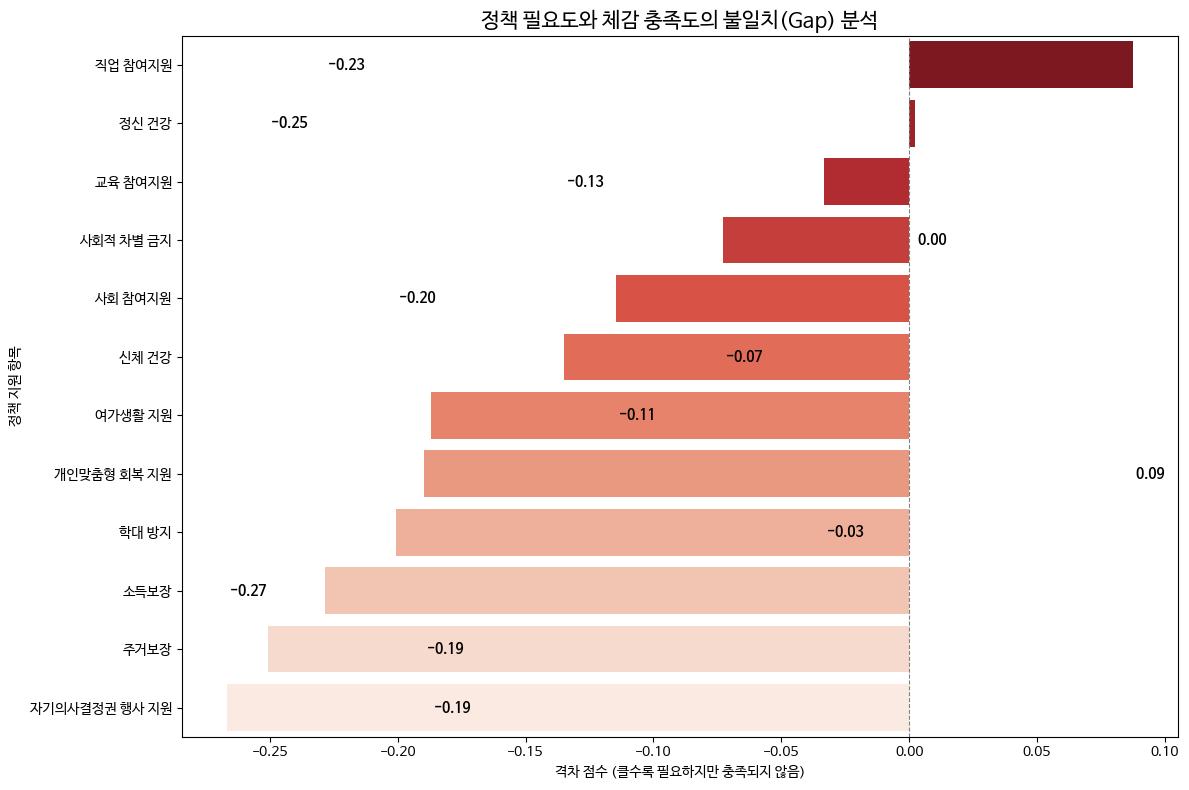

/usr/local/lib/python3.12/dist-packages/matplotlib/collections.py:1008: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


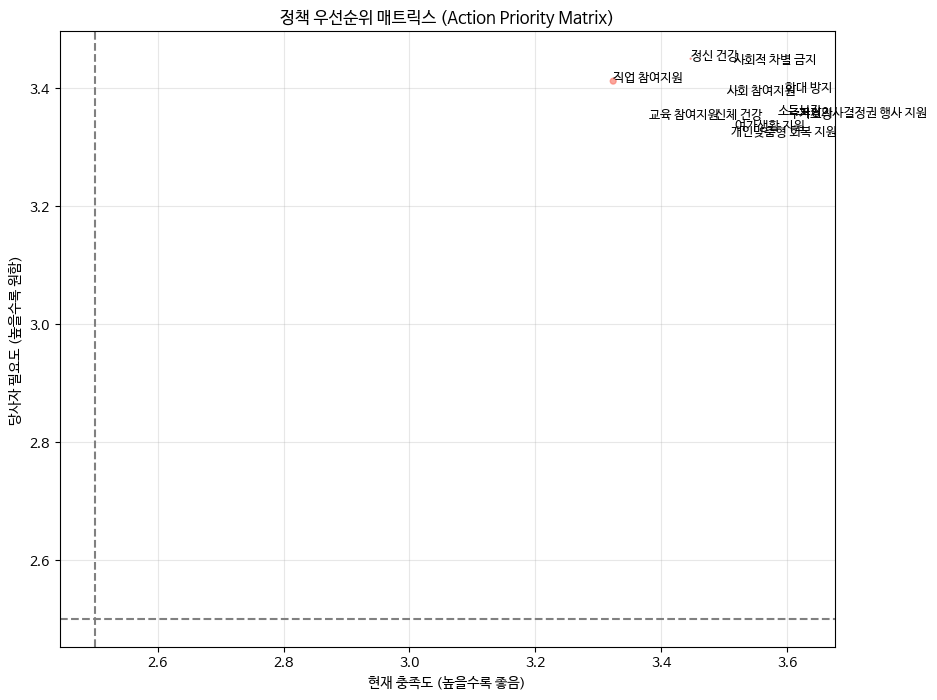

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import platform
import numpy as np

# ---------------------------------------------------------
# 1. 폰트 및 데이터 설정
# ---------------------------------------------------------
plt.rc('font', family='NanumBarunGothic')
plt.rc('axes', unicode_minus=False)

filename = 'renamed_data.csv'
try:
    df = pd.read_csv(filename, encoding='utf-8')
except:
    df = pd.read_csv(filename, encoding='cp949')

# ---------------------------------------------------------
# 2. '필요도'와 '충족도' 관련 문항 쌍(Pair) 찾기
# ---------------------------------------------------------
# 데이터 컬럼명에 '필요'와 '충분'이 포함된 컬럼을 찾습니다.
# (데이터 구조에 따라 '지원제도(필요)_항목명' 형태라고 가정하고 매칭합니다)

cols_need = [c for c in df.columns if '필요' in c and '지원' in c]
cols_suff = [c for c in df.columns if '충분' in c and '지원' in c]

print(f"필요도 문항 개수: {len(cols_need)}")
print(f"충족도 문항 개수: {len(cols_suff)}")

# ---------------------------------------------------------
# 3. 데이터 점수화 (4점 척도 변환)
# ---------------------------------------------------------
score_map = {
    # 필요도
    '매우 필요': 4, '필요': 3, '필요하지 않음': 2, '전혀 필요하지 않음': 1,
    '매우 필요함': 4, '필요함': 3,
    # 충족도
    '충분': 4, '대체로 충분': 3, '불충분': 2, '전혀 안 됨': 1,
    '매우 충분': 4, '부족': 2, '매우 부족': 1,
    '전혀 그렇지 않다': 1, '그렇지 않다': 2, '그렇다': 3, '매우 그렇다': 4
}

# 분석용 데이터셋 만들기
df_gap = df[cols_need + cols_suff].copy()
df_gap = df_gap.replace(score_map)
df_gap = df_gap.apply(pd.to_numeric, errors='coerce')

# ---------------------------------------------------------
# 4. 항목별 평균 점수 및 격차(Gap) 계산
# ---------------------------------------------------------
results = []

# 문항 이름에서 공통된 '주제(키워드)'를 추출하여 매칭
# 예: "지원제도(필요)_가족지원" -> "가족지원"
for col_n in cols_need:
    # 키워드 추출 (괄호나 앞부분 제거)
    keyword = col_n.split('_')[-1] # 언더바(_) 뒤의 단어를 키워드로 가정

    # 충족도 컬럼 중에서 같은 키워드를 가진 것 찾기
    match_s = [c for c in cols_suff if keyword in c]

    if match_s:
        col_s = match_s[0]

        mean_need = df_gap[col_n].mean()
        mean_suff = df_gap[col_s].mean()
        gap = mean_need - mean_suff # 격차 = 필요 - 충분

        results.append({
            '정책 항목': keyword,
            '필요도(Need)': mean_need,
            '충족도(Sufficiency)': mean_suff,
            '격차(Gap)': gap
        })

df_result = pd.DataFrame(results)
df_result = df_result.sort_values('격차(Gap)', ascending=False) # 격차가 큰 순서대로 정렬

print("\n" + "="*50)
print("   [정책 사각지대 순위 (Gap이 클수록 시급함)]")
print("="*50)
print(df_result[['정책 항목', '필요도(Need)', '충족도(Sufficiency)', '격차(Gap)']].round(2))

# ---------------------------------------------------------
# 5. 시각화 (덤벨 차트 & 막대 그래프)
# ---------------------------------------------------------
plt.figure(figsize=(12, 8))

# 격차(Gap) 막대 그래프
sns.barplot(data=df_result, x='격차(Gap)', y='정책 항목', palette='Reds_r')

# 기준선 표시
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title('정책 필요도와 체감 충족도의 불일치(Gap) 분석', fontsize=15)
plt.xlabel('격차 점수 (클수록 필요하지만 충족되지 않음)')
plt.ylabel('정책 지원 항목')

# 수치 표시
for index, row in df_result.iterrows():
    # 그래프 상 좌표 매칭이 까다로울 수 있어 간단히 텍스트 위치 조정
    plt.text(row['격차(Gap)'], index, f" {row['격차(Gap)']:.2f}",
             va='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. 산점도 (Action Matrix)
# ---------------------------------------------------------
# X축: 충족도, Y축: 필요도 -> 4분면 분석
plt.figure(figsize=(10, 8))
plt.scatter(df_result['충족도(Sufficiency)'], df_result['필요도(Need)'],
            s=df_result['격차(Gap)']*200, color='salmon', alpha=0.7)

# 각 점에 이름표 달기
for i, row in df_result.iterrows():
    plt.text(row['충족도(Sufficiency)'], row['필요도(Need)'], row['정책 항목'], fontsize=9)

# 4분면 기준선 (중간값인 2.5점 기준)
plt.axhline(2.5, color='gray', linestyle='--')
plt.axvline(2.5, color='gray', linestyle='--')

plt.title('정책 우선순위 매트릭스 (Action Priority Matrix)')
plt.xlabel('현재 충족도 (높을수록 좋음)')
plt.ylabel('당사자 필요도 (높을수록 원함)')
plt.grid(True, alpha=0.3)
plt.show()

한글 폰트 설정 완료.

--- 'renamed_data.csv' 파일을 업로드하세요 ---


Saving renamed_data.csv to renamed_data (7).csv

'renamed_data (7).csv' 파일 로드 성공!

   [경제 그룹별 자존감 및 장벽 인식 평균 비교]
                자존감  일자리 부족  가족 부담감(통합)
경제그룹                                   
비수급자 (경제적 안정)  3.00    2.90        2.73
수급자 (경제적 취약)   3.02    3.15        2.98

(요청에 의해 분석 1의 그래프는 생략되었습니다.)

   [수급자(취약계층) 내부 심층 분석]
▶ '일자리 부족하다고 느낄수록' <-> '가족에게 부담된다고 느끼는가?'
▶ 상관계수 (r): 0.448
>> 해석: 뚜렷한 양의 상관관계. 일자리가 없다는 현실적 장벽이 가족에 대한 심리적 부담감을 높이고 있습니다.
>> 시사점: '일자리 제공'이 곧 '가족 부담감 해소'의 열쇠입니다.


/tmp/ipython-input-2537266275.py:63: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[key] = df[col].replace(score_map_barrier).apply(pd.to_numeric, errors='coerce')
/tmp/ipython-input-2537266275.py:63: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[key] = df[col].replace(score_map_barrier).apply(pd.to_numeric, errors='coerce')
/tmp/ipython-input-2537266275.py:63: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objec

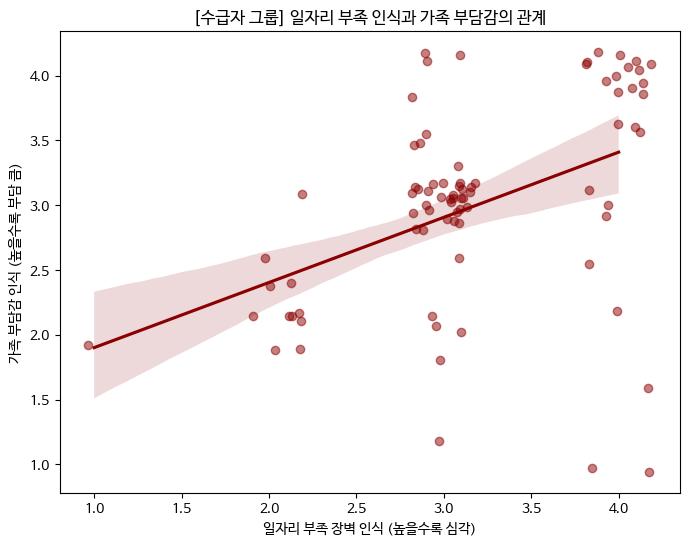

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files
import numpy as np

# ---------------------------------------------------------
# 1. 폰트 및 데이터 설정 (파일 업로드 기능 포함)
# ---------------------------------------------------------
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False
print("한글 폰트 설정 완료.")

# 파일 업로드
print("\n--- 'renamed_data.csv' 파일을 업로드하세요 ---")
try:
    # (파일이 이미 업로드되어 있다면 이 부분은 건너뛰고 캐시된 파일을 사용합니다)
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df = pd.read_csv(file_name)
    print(f"\n'{file_name}' 파일 로드 성공!")
except Exception as e:
    # 이전에 업로드한 df가 메모리에 남아있다면 재사용
    if 'df' in locals():
        print("이전에 업로드한 데이터를 재사용합니다.")
    else:
        print(f"파일 로드 중 오류 발생: {e}")
        df = pd.DataFrame()

# ---------------------------------------------------------
# 2. 분석 대상 컬럼 정의 및 전처리
# ---------------------------------------------------------
if not df.empty:
    # (1) 그룹 구분: 기초생활수급 여부 (경제적 상태 대리변수)
    col_welfare = '국민기초생활보장수급 상태 및 유형'

    def classify_group(val):
        val = str(val)
        if '수급대상 아님' in val or ('해당' in val and '없음' in val):
            return '비수급자 (경제적 안정)'
        elif '수급' in val:
            return '수급자 (경제적 취약)'
        else:
            return np.nan # 분류 불가

    df['경제그룹'] = df[col_welfare].apply(classify_group)
    df = df.dropna(subset=['경제그룹']) # 분류 안된 데이터 제거

    # (2) 탈원화 장벽 (일자리, 가족부담) -> 점수화
    cols_barriers = {
        '일자리 부족': '탈원화장벽: 일자리 부족',
        '가족 돌봄 부담(지역사회)': '탈원화장벽: 지역사회 생활 시 가족 돌봄 부담 큼',
        '가족 돌봄 부담(퇴원시)': '탈원화장벽: 퇴원/퇴소 시 가족 돌봄 부담 큼'
    }

    score_map_barrier = {
        '매우 그렇다': 4, '그렇다': 3, '그렇지 않다': 2, '전혀 그렇지 않다': 1,
        '매우 큼': 4, '큼': 3, '작음': 2, '전혀 없음': 1
    }

    for key, col in cols_barriers.items():
        if col in df.columns:
            df[key] = df[col].replace(score_map_barrier).apply(pd.to_numeric, errors='coerce')

    # 가족 부담 통합 점수 (두 문항 평균)
    if '가족 돌봄 부담(지역사회)' in df.columns and '가족 돌봄 부담(퇴원시)' in df.columns:
        df['가족 부담감(통합)'] = df[['가족 돌봄 부담(지역사회)', '가족 돌봄 부담(퇴원시)']].mean(axis=1)

    # (3) 자존감 점수
    cols_self = [
        '회복(MHRM5): 나 자신을 믿는다',
        '회복(MHRM10): 어려움 있어도 가치 있는 존재',
        '회복(MHRM16): 나 자신을 좋아한다',
        '회복(MHRM19): 나 자신에 대해 편안하게 느낌'
    ]
    map_self = {'매우 그렇다': 4, '그렇다': 3, '그렇지 않다': 2, '전혀 그렇지 않다': 1}

    # 존재하는 컬럼만 선택하여 계산
    valid_cols_self = [c for c in cols_self if c in df.columns]
    if valid_cols_self:
        df['자존감'] = df[valid_cols_self].replace(map_self).apply(pd.to_numeric, errors='coerce').mean(axis=1)

    # ---------------------------------------------------------
    # 3. [분석 1] 수급자 vs 비수급자 자존감 & 장벽 인식 비교 (그래프 삭제됨)
    # ---------------------------------------------------------
    if '자존감' in df.columns and '일자리 부족' in df.columns and '가족 부담감(통합)' in df.columns:
        group_stats = df.groupby('경제그룹')[['자존감', '일자리 부족', '가족 부담감(통합)']].mean()

        print("\n" + "="*50)
        print("   [경제 그룹별 자존감 및 장벽 인식 평균 비교]")
        print("="*50)
        print(group_stats.round(2))
        print("\n(요청에 의해 분석 1의 그래프는 생략되었습니다.)")

    # ---------------------------------------------------------
    # 4. [분석 2] 수급자 내부 분석: 일자리 부족 인식 <-> 가족 부담감 상관관계
    # ---------------------------------------------------------
    # 수급자 그룹만 추출
    df_recipient = df[df['경제그룹'] == '수급자 (경제적 취약)']

    if not df_recipient.empty and '일자리 부족' in df_recipient.columns and '가족 부담감(통합)' in df_recipient.columns:
        # 상관관계 분석
        corr_job_burden = df_recipient['일자리 부족'].corr(df_recipient['가족 부담감(통합)'])

        print("\n" + "="*50)
        print("   [수급자(취약계층) 내부 심층 분석]")
        print("="*50)
        print(f"▶ '일자리 부족하다고 느낄수록' <-> '가족에게 부담된다고 느끼는가?'")
        print(f"▶ 상관계수 (r): {corr_job_burden:.3f}")

        # [수정] '죄책감' 단어 제거 및 순화
        if corr_job_burden > 0.3:
            print(">> 해석: 뚜렷한 양의 상관관계. 일자리가 없다는 현실적 장벽이 가족에 대한 심리적 부담감을 높이고 있습니다.")
            print(">> 시사점: '일자리 제공'이 곧 '가족 부담감 해소'의 열쇠입니다.")
        else:
            print(">> 해석: 두 인식 간의 직접적 상관성은 약하게 나타났습니다.")

        # 산점도 시각화
        plt.figure(figsize=(8, 6))

        # [수정] 라벨에서 죄책감 제거
        sns.regplot(data=df_recipient, x='일자리 부족', y='가족 부담감(통합)',
                    x_jitter=0.2, y_jitter=0.2, scatter_kws={'alpha':0.5}, color='darkred')

        plt.title('[수급자 그룹] 일자리 부족 인식과 가족 부담감의 관계')
        plt.xlabel('일자리 부족 장벽 인식 (높을수록 심각)')
        plt.ylabel('가족 부담감 인식 (높을수록 부담 큼)') # 라벨 수정
        plt.show()
    else:
        print("분석에 필요한 데이터가 충분하지 않습니다.")